# Task 3

In [52]:
import numpy as np
import pygad
import matplotlib.pyplot as plt
import pandas as pd
import json

In [53]:
def read_txt_to_dict(path):

    # Dictionary
    slovar = dict()

    # Open the file
    with open(path, 'r') as file:
        
        for line in file:
            
            # Cleaning the line
            splited = line.replace(",", "").replace("[", "").replace("]", "").replace("\n", "").split()
            
            # Filling dictionary
            slovar[splited[0]] = splited[1:]
            
    return slovar


def load_preferences(folder):
    preferences = dict()
    with open(f"{folder}\\Preferences.txt", 'r', encoding="utf-8") as file:
        for line in file:
            # Splits only by first space
            name, string = line.split(" ", 1)
            string = string.replace("“", '"').replace("”", '"')
            preferences[name] = json.loads(string)
    return preferences

preferences = load_preferences("Data")
print("preferences:", preferences)

# print(preferences["Anna"]["likes"][0])
        

preferences: {'Anna': {'likes': [10, 11], 'dislikes': [12, 14]}, 'Brian': {'likes': [10, 14], 'dislikes': [15, 16]}, 'Charles': {'likes': [10, 11], 'dislikes': [12, 16]}, 'Diana': {'likes': [10, 14], 'dislikes': [15, 16]}}


In [54]:

def load_data(folder):

    classes = read_txt_to_dict(f"{folder}\\Classes.txt")
    classrooms = read_txt_to_dict(f"{folder}\\Classrooms.txt")
    teachers = read_txt_to_dict(f"{folder}\\Teachers.txt")

    print("classes:",classes)
    print("classrooms:", classrooms)
    print("teachers:",teachers)
    print()

    idClasses = []
    globalIdClassDictionary = {}
    slovarTrajanjaUr = {}
    # lecture id -> class index, For more lectures of same class -> to know from which class 
    lectureClass = {} 
    idLecture = 0
    indexClass = {}

    for id, nameClass in enumerate(classes):
        # Duration of specific lecture in class
        for duration in classes[nameClass]: 
            idClasses.append(idLecture)
            slovarTrajanjaUr[idLecture] = int(duration)
            lectureClass[idLecture] = id
            # Class name - hourTime - id
            globalIdClassDictionary[idLecture] = f"{nameClass}-{idLecture} ({duration})"
            idLecture+=1

        # added class index - for teachers
        indexClass[nameClass] = id


    # Classroom Index: 0:P1, 1:P2, 2:P3, 3:P4
    # classroomTime: on index x is start_time and end_time
    idClassroom = []
    classroomTime = []
    globalIdClassroomsDictionary = {}

    for id, clas in enumerate(classrooms):
        # Duration (from when to when open)
        c = classrooms[clas]
        classroomTime.append([int(c[0]), int(c[1])])

        globalIdClassroomsDictionary[id] = f"{clas} ({c[0]}-{c[1]})"

        idClassroom.append(id)

    # Teacher Index: Anna:0, Brian:1, Charles:2, Diana:3
    # teacherClass: on index x are avaible classes that that teacher teachs (ony the first index x)
    idTeacher = []
    teacherClass = []
    globalIdTeachersDictionary = {}

    for id, t in enumerate(teachers):
        idTeacher.append(id)

        globalIdTeachersDictionary[id] = t

        # Which lectures indexed for teachers
        h = []
        for lecture in teachers[t]:
            # Index of a class
            # {"Programming":0, "Math":1, "Algorithms":2, "OperatingSystems":3}
            h.append(indexClass[lecture])

        teacherClass.append(h)

    return (idClasses, slovarTrajanjaUr, lectureClass, globalIdClassDictionary,
            idClassroom, classroomTime, globalIdClassroomsDictionary,
            idTeacher, teacherClass, globalIdTeachersDictionary)


(idClasses, slovarTrajanjaUr, lectureClass, globalIdClassDictionary,
idClassroom, classroomTime, globalIdClassroomsDictionary,
idTeacher, teacherClass, globalIdTeachersDictionary) = load_data("Data")

print("idClasses:", idClasses, " -  SlovarTrajanjaUr:", slovarTrajanjaUr)
print("idClassroom:", idClassroom, " -  classroomTime" ,classroomTime)
print("idTeacher:", idTeacher, " -  teacherClass:", teacherClass)
print("lectureClass:", lectureClass,"\n")


# For decoding
print("globalIdClassDictionary", globalIdClassDictionary)
print("globalIdClassroomsDictionary", globalIdClassroomsDictionary)
print("globalIdTeachersDictionary", globalIdTeachersDictionary)

classes: {'Programming': ['2', '3', '2', '2'], 'Math': ['2', '2'], 'Algorithms': ['2', '3'], 'OperatingSystems': ['2', '2']}
classrooms: {'P1': ['10', '16'], 'P2': ['8', '16'], 'P3': ['10', '16'], 'P4': ['10', '16']}
teachers: {'Anna': ['Programming', 'Math'], 'Brian': ['Programming', 'Algorithms', 'OperatingSystems'], 'Charles': ['Math'], 'Diana': ['Algorithms', 'OperatingSystems']}

idClasses: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]  -  SlovarTrajanjaUr: {0: 2, 1: 3, 2: 2, 3: 2, 4: 2, 5: 2, 6: 2, 7: 3, 8: 2, 9: 2}
idClassroom: [0, 1, 2, 3]  -  classroomTime [[10, 16], [8, 16], [10, 16], [10, 16]]
idTeacher: [0, 1, 2, 3]  -  teacherClass: [[0, 1], [0, 2, 3], [1], [2, 3]]
lectureClass: {0: 0, 1: 0, 2: 0, 3: 0, 4: 1, 5: 1, 6: 2, 7: 2, 8: 3, 9: 3} 

globalIdClassDictionary {0: 'Programming-0 (2)', 1: 'Programming-1 (3)', 2: 'Programming-2 (2)', 3: 'Programming-3 (2)', 4: 'Math-4 (2)', 5: 'Math-5 (2)', 6: 'Algorithms-6 (2)', 7: 'Algorithms-7 (3)', 8: 'OperatingSystems-8 (2)', 9: 'OperatingSystems-

In [55]:
# From https://pygad.readthedocs.io/en/latest/custom_functions.html
import time

# How quickly does the fitness score increase
fitnessScores = []

# Adding time to a dictionary
timeDictionary = {
    "overhead": 0, "parents": 0, "crossover": 0, "mutation": 0, "fitness": 0,
    "latest_call_back": 0
}

# When GA starts
def on_start(ga_instance):
    # Reseting
    fitnessScores.clear()
    # Reseting to zero
    for key in timeDictionary:
        timeDictionary[key] = 0
    # Setting the time when GA starts
    timeDictionary["latest_call_back"] = time.perf_counter()

# When fitness score is calculated
def on_fitness(ga_instance, last_gen_fitness):

    call_back = time.perf_counter()
    # call_back - latest_call_back = time that it took to complete this step!
    # We sum together, average in the end
    timeDictionary["overhead"] += call_back - timeDictionary["latest_call_back"]
    
    # Save last callback
    timeDictionary["latest_call_back"] = call_back

# After parents selection
def on_parents(ga_instance, last_gen_parents):
    
    call_back = time.perf_counter()
    timeDictionary["parents"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

# After crossover is finished
def on_crossover(ga_instance, last_gen_offspring):
    
    call_back = time.perf_counter()
    timeDictionary["crossover"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

# After mutation
def on_mutation(ga_instance, last_gen_offspring):
        
    call_back = time.perf_counter()
    timeDictionary["mutation"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

# At the end of the generation
# fitness time calculated before on_generation and it fell into generation bucket
def on_generation(ga_instance):

    call_back = time.perf_counter()
    timeDictionary["fitness"] += call_back - timeDictionary["latest_call_back"]
    timeDictionary["latest_call_back"] = call_back

    # gives max fitness 
    fitnessScores.append(ga_instance.last_generation_fitness.max())

In [56]:

# FOR MULTI OBJECTIVE OPTIMIZATION
def fSoft(teacherSpots):
    
    # SOFT constraints from task 3
    # • Teacher preferences
    # If one of thoose constarints its right i will lower/increase fitness score!
    # I will use teacherSpots from previus solutions
    
    teachingHours = []
    issue = 0
    for t in idTeacher:
    
        # get their name
        name = globalIdTeachersDictionary[t]

        # Which time she dis/likes
        likes = preferences[name]["likes"]
        dislikes = preferences[name]["dislikes"]

        # if spots aren't selected they are 0 so no affect
        # If spots she likes are selected (we subtract that amount)
        # [10,11] -> hour 10 is only countzed, [10,14] -> 10,11,12,13
        # 0.1 so (at other values, this influenced other problems, like overlaping classes)
        issue -= 0.10 * np.sum(teacherSpots[t][likes[0]:likes[1]])

        # If spots she DISlikes are selected (we increase that amount)
        # * 0.25 to lower the importance (at 0.5 this influenced other problems, like overlaping classes to occour)
        issue += 0.25 * np.sum(teacherSpots[t][dislikes[0]:dislikes[1]])
    
    
        # • Teacher balance: everyone teaches (approximately) the same number of hours.
        # Number of hours that a t teacher teachs
        num = np.sum(teacherSpots[t])
        teachingHours.append(num)
    
        
    # Penalizing where teachers are far from average nnumber of teaching hours
    avgTeachingHours = np.mean(teachingHours)
    
    # For every teacher (teaching Hours)
    for th in teachingHours:
    
        # a difference between avg and current teaching hours from teacher t
        # Than multiply by 0.25 for each difference
        issue += np.ceil(abs(th - avgTeachingHours)) * 0.25


    return issue


# suitable fitness function that will reward schedules that satisfy the conditions and penalize those that do not.
# (idClass, idClassroom, start, idteacher)
def f(schedule, multiObjectOptimization=False):

    # (idClass, idClassroom, start, idteacher)

    # Global count fitness score
    issue = 0

    # • Every lecture in the classes file must be present in the schedule
    for cid in idClasses:
        find = 0    
        
        # Find if exists 
        for lecture in schedule:
            if lecture[0] == cid: 
                find += 1
            
        # If one lecture/class is not found penatly is high
        if find == 0: 
            issue += 10

        # If some duplicates
        if find > 1:
            issue += 10


    # Every lecture needs to be assigned to a classroom at a time when that classroom is available. 
    # Filled spots (za vsako učilnico toliko pozicij kot ur)
    # Array is build 0 - unocupied , 1 - occupied and >1 means more lectures same time
    spots = [ [ 0 for j in range(razred[1]-razred[0])] for razred in classroomTime]
    
    # Teachers hours (from 0 to 24) -> that many spots
    teacherSpots = [ [0 for j in range(24)] for _ in idTeacher]

    for lec in schedule:
                
        id_Class, id_Classroom, startHour, id_Teacher = lec
        # You cannot index by float round number
        id_Class, id_Classroom, startHour, id_Teacher = int(id_Class), int(id_Classroom), int(startHour), int(id_Teacher)
    
        # From slovar of hours, I get duration of this class 
        endHour = startHour + slovarTrajanjaUr[id_Class]
    
        # What index should it fill (Normalizing so it starts with 0 - for array)
        startIndToFill = startHour - classroomTime[id_Classroom][0]
        endIndToFill = endHour - classroomTime[id_Classroom][0]

        # For how many hours the classroom is open
        dolg = classroomTime[id_Classroom][1] - classroomTime[id_Classroom][0]

        # if the class starts before the classroom opens - penatly (that many hours that is late - increment issue)
        if startHour < classroomTime[id_Classroom][0]:       
            issue += abs(classroomTime[id_Classroom][0] - startHour) * 6            

        # if class goes longer than the classroom is open. (14-17) = 14,15,16     
        if endHour > classroomTime[id_Classroom][1]:
            issue += (endHour - classroomTime[id_Classroom][1]) * 6
        
        
        validStart = max(startIndToFill, 0)
        validEnd = min(endIndToFill, dolg)
       
        # Fill the spots and check for overlaping 
        # 10-12 -> increments 10, 11
        for i in range(validStart, validEnd):
            spots[id_Classroom][i]+=1

            # Lectures cannot overlap in the same classroom: a single classroom can hold only a single lecture in a given hour.
            # For every value that is more than 1 -> *3 per overlap
            if spots[id_Classroom][i] > 1: issue += 3 * (spots[id_Classroom][i] - 1)

        # Teachers cannot teach more than one lecture at the same time. (So across all the classrooms in a day)
        for i in range(startHour, min(endHour, 24)):
            # If teacher already has a class at that hour
            if teacherSpots[id_Teacher][i] > 0:
                issue += 3
            teacherSpots[id_Teacher][i] += 1


        # Every lecture needs to be assigned a teacher (That teaches that class) 
        # Which classes can the teacher teach
        canTeach = teacherClass[id_Teacher]
        teachingClass = lectureClass[id_Class]

        if teachingClass not in canTeach:
            issue+=10


    # So default approach, only one function, no multiObjects
    if not multiObjectOptimization:
        issue += fSoft(teacherSpots)

       
    return issue, teacherSpots

# Negating the value to minimize the fitness_score (in this case error rate)
def fitness_function(ga_instance, solution, x_idx):

    # solution is flat so I had to make it 2D
    schedule = [solution[i:i+4] for i in range(0, len(solution), 4)]

    score, _ = f(schedule)
    
    return -score


# multi objective optimization -> so multi fitness function 
def multi_fitness_function(ga_instance, solution, x_idx):
    
    # solution is flat so I had to make it 2D
    schedule = [solution[i:i+4] for i in range(0, len(solution), 4)]

    scoreHardConst, teacherSpots = f(schedule, multiObjectOptimization=True)
    scoreSoftConts = fSoft(teacherSpots)

    # As in provided link
    # [-53, 0.1] can beat [-6, -0.5], even thought hard constraints are more important so
    # they both beat eachother -53 < -6 and 0.1 > -0.5, so the solution which is closer to zero wins
    # i just hardcoded that scoreHardConst must be 0 for right schedule (if not than sum together hardScoreConts + softScoreConst)
    
    # schedule is not good for hard constraints -> penalize with adding it to scoreSoftConst
    if scoreHardConst > 0:
        scoreSoftConts = scoreSoftConts + (scoreHardConst)
    

    return [-scoreHardConst, -scoreSoftConts]

In [ ]:
import random

# Generating your own initial population. (so generating some valid schedule (or almost valid))
# Better than the GA generated
# I will build valid for first 2 constraint (for teachers it gets more complicated) -> but for teacher who can teach only x class WILL DO
def initialPopulationFunc():

    arrayClasses = np.copy(idClasses)

    schedule = []
    # startHour: When does class starts, classroomIndex -> which classroom are we in now
    start_Hour = classroomTime[0][0]
    classroomIndex = 0

    # To know how much did we already add lectures (in a row)
    # Example: idclassroom 0 filled with 6h (8-16) -> now 8-14 
    offsetStartClassroom = [0 for i in range(len(idClassroom))]

    # Adding each class to some avaible classroom (random)
    for _ in arrayClasses:

        # Select a random class
        id_Class = random.choice(arrayClasses)

        # Remove that class from array (to not pick it again)
        arrayClasses = arrayClasses[arrayClasses != id_Class]

        # If it doesn't fit
        triedClassrooms  = 0
        possible = True

        # Get avaible classroom (when can it start) (should all fit -> loop continuesly)
        # Till this class fit to some classroom
        while start_Hour + slovarTrajanjaUr[id_Class] > classroomTime[classroomIndex][1]:

            # tried all classrooms -> cant fit
            if triedClassrooms  == len(idClassroom):
                possible = False
                break

            # To not over indexed (so in a loop)
            classroomIndex += 1 
            classroomIndex %= len(idClassroom)

            # When the classroom is still free (from what time)
            start_Hour = classroomTime[classroomIndex][0] + offsetStartClassroom[classroomIndex]
            triedClassrooms += 1

        if possible:
            lectureRoom, lectureStart = classroomIndex, start_Hour
        else :
            # if it doesnt fit -> we add to start of random class
            # gets penalized by fitness function
            lectureRoom = random.choice(idClassroom)
            lectureStart = classroomTime[lectureRoom][0]


        # Finding teacher that can teach this class (some variation where can it start)
        canTeach = []
        for i in range(len(teacherClass)):
        
            # If class is avaible to be teached by i teacher (from lecture to class)
            if lectureClass[id_Class] in teacherClass[i]:
                canTeach.append(i)
        
        # We select random teacher (i)
        # If there is a teacher that can teach
        if canTeach:
            indexOfTeacherThatCanTeach = random.choice(canTeach)
        # if not than just select a random -> fitness function will penalize it
        else:
            indexOfTeacherThatCanTeach = random.choice(idTeacher)
        
        # Adding to population (idClass, idClassroom, start, idteacher), ectending 1D array
        schedule.extend([id_Class, lectureRoom, lectureStart, indexOfTeacherThatCanTeach])

        # Save to when the class ends (only when placed normaly) and there is no problem
        if possible:
            start_Hour += slovarTrajanjaUr[id_Class]
            offsetStartClassroom[classroomIndex] += slovarTrajanjaUr[id_Class]


    # Returning schedule in numpy
    schedule = np.array(schedule).reshape(-1, 4) # 10 rows (idClass, idClassroom, start, idteacher)
    schedule = schedule[schedule[:, 0].argsort()] # sort by idClass

    # To 1D as input to GA
    return schedule.flatten()



# Using custom crossover operation. (didnt really use constraints here, beside grouping of 4)
# parents = num_parents_mating * (idClass, idClassroom, startHour, idTeacher)
# offspring_size = (the offspring size, number of genes)
# ga_instance = From it you can retrieve any proprety
def crossoverFunction(parents, offspring_size, ga_instance):
    
    # print(offspring_size.shape) -> (49 -> sol_per_pop, 40 -> 4 genes per 10 parents) -> 50 is best solution from previous generation
    # print(parents.shape) -> (10 -> parents_mating, 40 -> genes )

    offspring = []
    while len(offspring) != offspring_size[0]:

        # Random id of a parent (0...parent.shape[0]-1)
        idParent1 = random.randint(0, parents.shape[0]-1)
        idParent2 = random.randint(0, parents.shape[0]-1)

        # So the 2 indexes that are selected are different -> not the same parents
        while idParent2 == idParent1:
            idParent2 = random.randint(0, parents.shape[0]-1)

        # 2 solutions as parents - copy to not change original array
        parent1 = np.copy(parents[idParent1])
        parent2 = np.copy(parents[idParent2])

        # every 4 numbers are a one (idClass, idClassroom, startHour, idTeacher) for parent
        numberOfGenes = parents.shape[1] // 4   # 40 // 4 = 10
        crossoverIndex = random.randint(0, numberOfGenes-1) * 4 # 0,4,8,12

        # Preforming a crossover (take some from one and then from another one)
        # So not always the same grouping for 2 parents
        if random.randint(0,1) == 0:
            parent1[crossoverIndex:] = parent2[crossoverIndex:]
            # appending to new population till length of sol_per_pop
            offspring.append(parent1)
        
        else:
            parent2[crossoverIndex:] = parent1[crossoverIndex:]
            # appending to new population till length of sol_per_pop
            offspring.append(parent2)

    # Returns numpy array
    return np.array(offspring)


# Using custom mutation operation -> Most of the constraints into account.
def mutation_func(offspring, ga_instance):

    # Through each solution
    for chromosomeIdx in range(offspring.shape[0]): # 0..48

        # What gene to change (idClass, idClassroom, startHour, idTeacher)
        # Never select idClass -> we already have all
        classIdx  = random.randint(0, offspring.shape[1] // 4 - 1)
        parameterIdx = random.randint(1, 3)
        geneIdx = classIdx * 4 + parameterIdx

        
        # id of a class for that lecture where we mutate (to integer so we can index by it)
        id_Class = int(offspring[chromosomeIdx, geneIdx - parameterIdx])
        id_Classroom = int(offspring[chromosomeIdx, geneIdx - parameterIdx + 1])

        # Classes are all already in there from initial population so no need to mutate that

        # Changing idClassroom (swaping with different class)
        if parameterIdx == 1:
            classRoomIdx = random.choice(idClassroom)

            # Consider when classrom is open -> fix only when inside hours
            startHour = offspring[chromosomeIdx, geneIdx + 1]
            endHour = startHour + slovarTrajanjaUr[id_Class]
            # Skip if out of bounds
            if startHour < classroomTime[classRoomIdx][0] or endHour > classroomTime[classRoomIdx][1]:
                continue

            offspring[chromosomeIdx, geneIdx] = classRoomIdx
        
        # Start Hour (+1 -1 if that helps), but cannot be over the limits of a classroom
        # Changing lightly -> There are many cases where some class could be moved one hour up/down and still be valid
        elif parameterIdx == 2:
            
            startHour = offspring[chromosomeIdx, geneIdx]

            if random.randint(0,1) == 0:
                startHour -= 1

                # Starts before the classroom even opens, it stops and doesnt do anything -> goes into next loop
                if startHour < classroomTime[id_Classroom][0]:
                    continue
            
            else:
                startHour += 1
                endHour = startHour + slovarTrajanjaUr[id_Class]

                # Ends after the classroom closes, it stops and doesnt do anything -> goes into next loop
                if endHour > classroomTime[id_Classroom][1]:
                    continue

            # Saving a new value (updating)
            offspring[chromosomeIdx, geneIdx] = startHour


        # idTeacher (just swaping teachers)
        elif parameterIdx == 3:

            # Finding teacher that can teach this class (some variation where can it start)
            canTeach = []
            for i in range(len(teacherClass)):

                # If class is available to be teached by i teacher
                if lectureClass[id_Class] in teacherClass[i]:
                    canTeach.append(i)

            # We select random teacher (i)
            # nobody can teach this class -> keep the current teacher
            if not canTeach:
                continue
            id_Teacher = random.choice(canTeach)
    
            # Changing the teacher for that lecture
            offspring[chromosomeIdx, geneIdx] = id_Teacher
        
    
    return offspring


# generatedInitialPopulation = initialPopulationFunc()


In [79]:


# For each diff class id -> have a prebuilt gene space (idClass, idClassroom, start, idteacher)

earliest = min(t[0] for t in classroomTime)   # 8
latest   = max(t[1] for t in classroomTime)   # 16
startHours = list(range(earliest, latest))    # [8,..,15]

gene_space = []
for _ in range(len(idClasses)):
    # Extending array further 
    gene_space.extend([
        idClasses,
        idClassroom,
        # end hour will be calculated in fitness
        startHours,
        idTeacher
    ])

# configuring initial population (sol_per_pop)
sol_per_pop = 50
seed = 23
random.seed(seed)
initialPopulation = np.array( [initialPopulationFunc() for i in range(sol_per_pop)] )

# Genetic Algorithm (sol_per_pop - how many solutions exist in each generation.)
# single fitnes function - no nsga2
num_gener = 200
ga_instance = pygad.GA(

    fitness_func=fitness_function, 

    num_generations=num_gener,
    num_parents_mating=10,
    sol_per_pop=sol_per_pop,
    num_genes = len(gene_space),
    gene_space = gene_space,

    # Custom crossover
    crossover_type = crossoverFunction,

    # Custom mutation 
    mutation_type=mutation_func,  
    
    random_seed=seed,

    # Initial population - made by me
    initial_population=initialPopulation,

    # Same teacher for 2 objects, but different class/hour
    allow_duplicate_genes=True,
    
    # Callbaks
    on_start=on_start,
    on_fitness=on_fitness,
    on_parents=on_parents,
    on_crossover=on_crossover,
    on_mutation=on_mutation,
    on_generation=on_generation,
)

ga_instance.run()
solution, solution_fitness, solution_idx = ga_instance.best_solution()
print("Best parameter", solution)
print("Fitness", solution_fitness)
print("Index", solution_idx)


Best parameter [ 0.  3. 14.  0.  1.  3. 10.  0.  2.  2. 10.  1.  3.  0. 12.  1.  4.  0.
 10.  2.  5.  1. 12.  2.  6.  0. 14.  1.  7.  2. 12.  3.  8.  1. 10.  3.
  9.  1.  8.  3.]
Fitness -1.5
Index 0


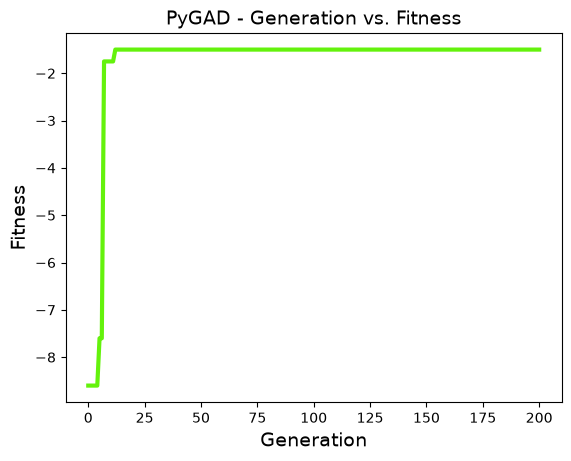

In [80]:
# ga_instance.plot_fitness()
ga_instance.plot_fitness();

In [81]:
def display_schedule(schedule):

    # Group lectures by classroom ID (so to sort them out)
    classrooms = {}
    for lec in schedule:
        
        idClass, idClassroom, startHour, idTeacher = lec
        # You cannot index by float round number
        idClass, idClassroom, startHour, idTeacher = int(idClass), int(idClassroom), int(startHour), int(idTeacher)

        # Saving all hours to a specific classroom - here we didn't yet found it
        if idClassroom not in classrooms:
            classrooms[idClassroom] = []

        #
        classrooms[idClassroom].append((startHour, idClass, idTeacher))


    # Sort classrooms by ID for output
    for idClassroom in sorted(classrooms.keys()):

        # Names
        classroomName = globalIdClassroomsDictionary[idClassroom]
        
        print(f"\n{classroomName}")
        print("-" * 40)
        
        # Sort lectures in this classroom by start hour (in order)
        lectures = sorted(classrooms[idClassroom], key=lambda x: x[0])

        for start_hour, id_class, id_teacher in lectures:

            # Decoding from indexes to names
            classsName = globalIdClassDictionary[id_class]
            teachername = globalIdTeachersDictionary[id_teacher]
            endHour = start_hour + slovarTrajanjaUr[id_class]

            # Text Representation
            print(f"  [ {start_hour:02d}:00 - {endHour:02d}:00 ] -> {classsName} (Taught by: {teachername})")


# Generated schedule for initial population
# L = [generatedInitialPopulation[i:i+4] for i in range(0, len(generatedInitialPopulation), 4)]
# display_schedule(L)

schedule = [solution[i:i+4] for i in range(0, len(solution), 4)]
display_schedule(schedule)



P1 (10-16)
----------------------------------------
  [ 10:00 - 12:00 ] -> Math-4 (2) (Taught by: Charles)
  [ 12:00 - 14:00 ] -> Programming-3 (2) (Taught by: Brian)
  [ 14:00 - 16:00 ] -> Algorithms-6 (2) (Taught by: Brian)

P2 (8-16)
----------------------------------------
  [ 08:00 - 10:00 ] -> OperatingSystems-9 (2) (Taught by: Diana)
  [ 10:00 - 12:00 ] -> OperatingSystems-8 (2) (Taught by: Diana)
  [ 12:00 - 14:00 ] -> Math-5 (2) (Taught by: Charles)

P3 (10-16)
----------------------------------------
  [ 10:00 - 12:00 ] -> Programming-2 (2) (Taught by: Brian)
  [ 12:00 - 15:00 ] -> Algorithms-7 (3) (Taught by: Diana)

P4 (10-16)
----------------------------------------
  [ 10:00 - 13:00 ] -> Programming-1 (3) (Taught by: Anna)
  [ 14:00 - 16:00 ] -> Programming-0 (2) (Taught by: Anna)


overhead: 0.0061 s -> avg per step: 0.0304 ms
parents: 0.0421 s -> avg per step: 0.2105 ms
crossover: 0.0347 s -> avg per step: 0.1734 ms
mutation: 0.0152 s -> avg per step: 0.0762 ms
fitness: 0.6398 s -> avg per step: 3.1988 ms


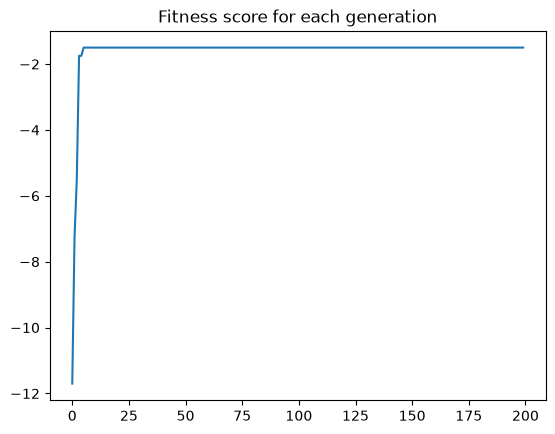

In [61]:
# Time of each step (lifecycle callbacks) <-> Average times
def printTimes():

    allTime = 0
    # For every callback
    for name, value in timeDictionary.items():

        # Ignore latest callback
        if name != "latest_call_back":
            
            # Averaging -> times
            avg = value / num_gener 
            allTime += value
            print(f"{name}: {value:.4f} s -> avg per step: {avg*1000:.4f} ms")

    # Ploting fitnes scores
    # print(fitnessScores)
    plt.plot(np.arange(0, len(fitnessScores)), fitnessScores)
    plt.title("Fitness score for each generation")
    plt.show()



printTimes()

#REVIEW: single fitness
# fitness -1.5 = 0 hard + 1.5 soft = valid
# Most of the soft constraints are taken into account
# Time increases for fitness function due to the soft constraints


In [75]:
# MULTI OBJECTIVE
seed1 = 23
random.seed(seed1)
initialPopulation = np.array( [initialPopulationFunc() for i in range(sol_per_pop)] )

# Genetic Algorithm (sol_per_pop - how many solutions exist in each generation.)
num_gener = 200
# Multi -objective optimization
ga_instance = pygad.GA(

    fitness_func=multi_fitness_function, 
    # For multi objective optimization
    parent_selection_type="nsga2",

    num_generations=num_gener,
    num_parents_mating=10,
    sol_per_pop=sol_per_pop,
    num_genes = len(gene_space),
    gene_space = gene_space,

    # Custom crossover
    crossover_type = crossoverFunction,

    # Custom mutation 
    mutation_type=mutation_func,  

    random_seed=seed1,

    # Initial population 
    initial_population=initialPopulation,

    # Same teacher for 2 objects, but different class/hour
    allow_duplicate_genes=True,
    
    # Callbaks
    on_start=on_start,
    on_fitness=on_fitness,
    on_parents=on_parents,
    on_crossover=on_crossover,
    on_mutation=on_mutation,
    on_generation=on_generation,
)

ga_instance.run()
solution, solution_fitness, solution_idx = ga_instance.best_solution()
print("Best parameter", solution)
print("Fitness", solution_fitness)
print("Index", solution_idx)



Best parameter [ 0.  1. 14.  0.  1.  3. 10.  0.  2.  2. 10.  1.  3.  0. 12.  1.  4.  0.
 10.  2.  5.  1. 12.  2.  6.  0. 14.  1.  7.  2. 12.  3.  8.  1. 10.  3.
  9.  1.  8.  3.]
Fitness [ 0.  -1.5]
Index 0


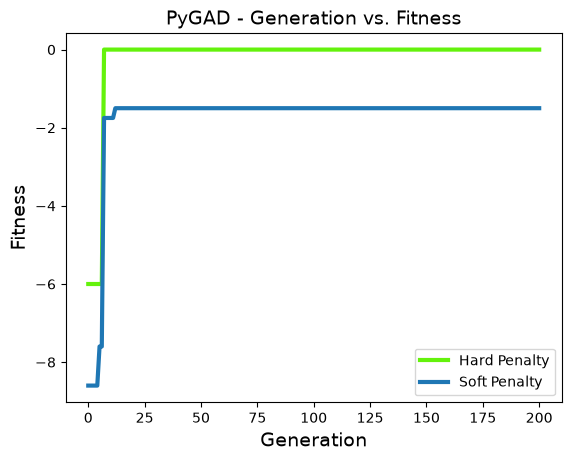

In [76]:
ga_instance.plot_fitness(label=["Hard Penalty", "Soft Penalty"]);

In [77]:
# display schedule for multi objective
schedule = [solution[i:i+4] for i in range(0, len(solution), 4)]
display_schedule(schedule)

hardPenalty = solution_fitness[0]
print("\nHard penalty:", hardPenalty, "-> valid" if hardPenalty == 0 else "-> NOT valid")
print("Soft penalty:", solution_fitness[1])


P1 (10-16)
----------------------------------------
  [ 10:00 - 12:00 ] -> Math-4 (2) (Taught by: Charles)
  [ 12:00 - 14:00 ] -> Programming-3 (2) (Taught by: Brian)
  [ 14:00 - 16:00 ] -> Algorithms-6 (2) (Taught by: Brian)

P2 (8-16)
----------------------------------------
  [ 08:00 - 10:00 ] -> OperatingSystems-9 (2) (Taught by: Diana)
  [ 10:00 - 12:00 ] -> OperatingSystems-8 (2) (Taught by: Diana)
  [ 12:00 - 14:00 ] -> Math-5 (2) (Taught by: Charles)
  [ 14:00 - 16:00 ] -> Programming-0 (2) (Taught by: Anna)

P3 (10-16)
----------------------------------------
  [ 10:00 - 12:00 ] -> Programming-2 (2) (Taught by: Brian)
  [ 12:00 - 15:00 ] -> Algorithms-7 (3) (Taught by: Diana)

P4 (10-16)
----------------------------------------
  [ 10:00 - 13:00 ] -> Programming-1 (3) (Taught by: Anna)

Hard penalty: 0.0 -> valid
Soft penalty: -1.5


overhead: 0.0379 s -> avg per step: 0.1896 ms
parents: 4.0629 s -> avg per step: 20.3143 ms
crossover: 0.0380 s -> avg per step: 0.1899 ms
mutation: 0.0162 s -> avg per step: 0.0812 ms
fitness: 4.7165 s -> avg per step: 23.5823 ms


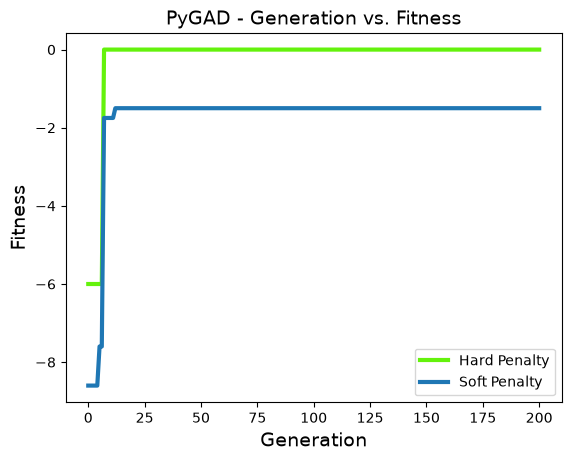

In [78]:
# Time of each step (lifecycle callbacks) <-> Average times
def printTimes():

    allTime = 0
    # For every callback
    for name, value in timeDictionary.items():

        # Ignore latest callback
        if name != "latest_call_back":
            
            # Averaging -> times
            avg = value / num_gener 
            allTime += value
            print(f"{name}: {value:.4f} s -> avg per step: {avg*1000:.4f} ms")

    # Ploting fitnes scores
    ga_instance.plot_fitness(label=["Hard Penalty", "Soft Penalty"]);



printTimes()
# REVIEW: 
# fitness [0, -1.5] -> valid schedule with some soft constarints taken into account 
# (all teacher mostly teach the same number of hours)
# Much slower on parents and fitness, because nsga2 sorting done twice per generation